# Assessing MESACLIP in the Arctic - Sea Ice SSPs

* **Description**: Reads in MESACLIP data for processing
* **Creator**: Alice DuVivier
* **Date**: December 2025

In [1]:
import xarray as xr
import numpy as np
import pandas as pd
from glob import glob
from datetime import datetime
import xesmf as xe
import matplotlib.pyplot as plt

import dask
from distributed import Client
from ncar_jobqueue import NCARCluster

## Spin up DASK cluster

In [2]:
# Create our NCAR Cluster - which uses PBSCluster under the hood
cluster = NCARCluster(walltime='2:00:00', cores=1, processes=1, memory='100 GB', 
                      resource_spec='select=1:ncpus=1:mem=100GB',interface='ext')

# Spin up 32 workers
cluster.scale(32)

# Assign the cluster to our Client
client = Client(cluster)

/glade/u/apps/opt/conda/envs/npl-2024a/lib/python3.11/site-packages/dask_jobqueue/core.py:255: FutureWarning: job_extra has been renamed to job_extra_directives. You are still using it (even if only set to []; please also check config files). If you did not set job_extra_directives yet, job_extra will be respected for now, but it will be removed in a future release. If you already set job_extra_directives, job_extra is ignored and you can remove it.
  warnings.warn(warn, FutureWarning)
/glade/u/apps/opt/conda/envs/npl-2024a/lib/python3.11/site-packages/dask_jobqueue/core.py:274: FutureWarning: env_extra has been renamed to job_script_prologue. You are still using it (even if only set to []; please also check config files). If you did not set job_script_prologue yet, env_extra will be respected for now, but it will be removed in a future release. If you already set job_script_prologue, env_extra is ignored and you can remove it.
  warnings.warn(warn, FutureWarning)
/glade/u/apps/opt/con

In [3]:
client
# cluster.close()

Connection method: Cluster object,Cluster type: dask_jobqueue.PBSCluster
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/duvivier/PBS/proxy/35007/status,
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/duvivier/PBS/proxy/35007/status,Workers: 0
Total threads: 0,Total memory: 0 B
Comm: tcp://128.117.208.176:39609,Workers: 0
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/duvivier/PBS/proxy/35007/status,Total threads: 0
Started: Just now,Total memory: 0 B


## Set MESACLIP ensemble information

In [13]:
# Future
path_base= '/gdex/data/d651008/'
# list 10 members of MESACLIP - last one is the first and named differently
ens_mems = ['44-2006-2100.001', '44-2006-2100.002',
                '44-2006-2100.003', '46-2006-2100.004',
                '44-2006-2100.005', '46-2006-2100.006',
                '46-2006-2100.007', '46-2006-2100.008',
                '46-2006-2100.009', '46-2006-2100.010']

## Load in Data
- SIC (aice)

In [5]:
varname = 'aice'

In [14]:
%%time

print('loading historical data')
ds = xr.Dataset()

for m in ens_mems:
    print(m)
    # set case name
    case = 'b.e13.BRCP60C5.ne120_t12.cesm-ihesp-hires1.0.' + m
    # set data directory
    path = path_base+case+'/ice/proc/tseries/month_1'
    #print(path)
    # get list of files
    files = sorted(glob(f'{path}/{case}.cice.h.{varname}.??????-??????.nc'))       
    ds_tmp = xr.open_mfdataset(files, data_vars="minimal", coords='minimal', compat="override", parallel=True, 
                               concat_dim="time", combine='nested', decode_times=True)
    # take an average over the time bounds to get the right time dimension
    ds_tmp["time"] = ds_tmp.time_bounds.compute().mean(dim="d2")

    # keep only some variables
    keep_vars=['time','TLAT','TLON','tarea'] + [varname]
    ds_tmp = ds_tmp.drop_vars([v for v in ds_tmp.variables if v not in keep_vars])
    
    ds = xr.concat([ds,ds_tmp], dim='member_id')

loading historical data
44-2006-2100.001
44-2006-2100.002
44-2006-2100.003
46-2006-2100.004
44-2006-2100.005
46-2006-2100.006
46-2006-2100.007
46-2006-2100.008
46-2006-2100.009
46-2006-2100.010
CPU times: user 9.6 s, sys: 715 ms, total: 10.3 s
Wall time: 45.4 s


In [15]:
# for whatever reason, the first ensemble is null, eliminate it
ds = ds.sel(member_id=slice(1,11))

## Process Data

In [16]:
# save just lat and lon arrays since they are time invariant
lats = ds.TLAT.isel(member_id=0)
lons = ds.TLON.isel(member_id=0)
tarea = ds.tarea.isel(member_id=0)

/glade/u/apps/opt/conda/envs/npl-2024a/lib/python3.11/site-packages/distributed/client.py:3162: UserWarning: Sending large graph of size 329.65 MiB.
This may cause some slowdown.
Consider scattering data ahead of time and using futures.
  warnings.warn(


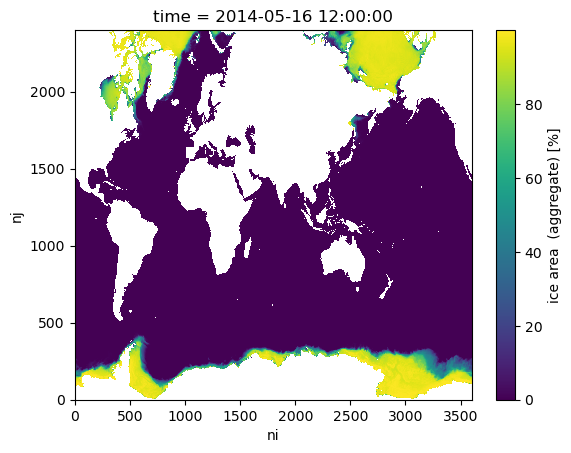

In [17]:
ds

# test plot
ds.aice.isel(member_id=0,time=100).plot()

/glade/u/apps/opt/conda/envs/npl-2024a/lib/python3.11/site-packages/distributed/client.py:3162: UserWarning: Sending large graph of size 164.82 MiB.
This may cause some slowdown.
Consider scattering data ahead of time and using futures.
  warnings.warn(
/glade/u/apps/opt/conda/envs/npl-2024a/lib/python3.11/site-packages/distributed/client.py:3162: UserWarning: Sending large graph of size 576.79 MiB.
This may cause some slowdown.
Consider scattering data ahead of time and using futures.
  warnings.warn(
/glade/u/apps/opt/conda/envs/npl-2024a/lib/python3.11/site-packages/distributed/client.py:3162: UserWarning: Sending large graph of size 164.82 MiB.
This may cause some slowdown.
Consider scattering data ahead of time and using futures.
  warnings.warn(
/glade/u/apps/opt/conda/envs/npl-2024a/lib/python3.11/site-packages/distributed/client.py:3162: UserWarning: Sending large graph of size 576.79 MiB.
This may cause some slowdown.
Consider scattering data ahead of time and using futures.
 

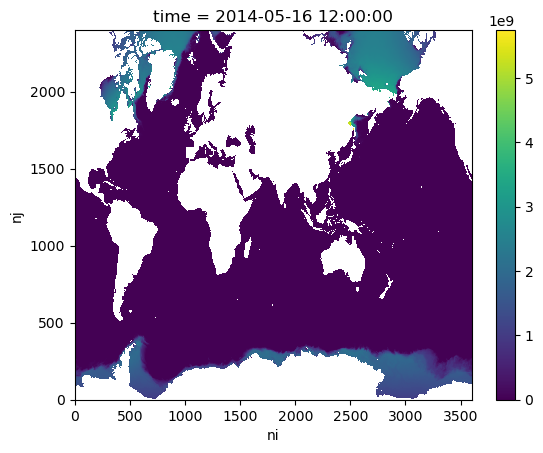

In [18]:
# multiply the points by tarea
ds_area = ds.aice * tarea

# test plot
ds_area.isel(member_id=0,time=100).plot()

/glade/u/apps/opt/conda/envs/npl-2024a/lib/python3.11/site-packages/distributed/client.py:3162: UserWarning: Sending large graph of size 329.71 MiB.
This may cause some slowdown.
Consider scattering data ahead of time and using futures.
  warnings.warn(


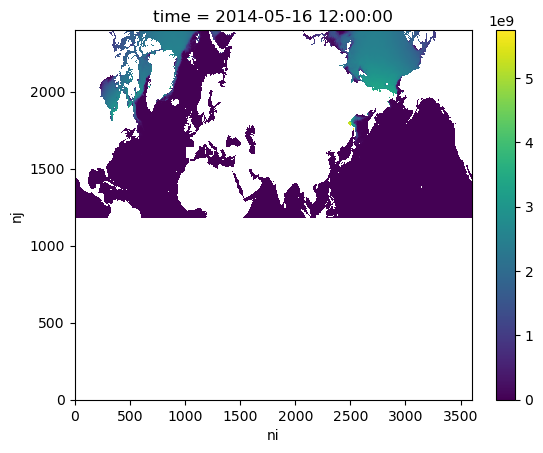

In [19]:
# mask just northern hemisphere
ds_area_nh = ds_area.where(lats > 0)

# test plot
ds_area_nh.isel(member_id=0,time=100).plot()

/glade/u/apps/opt/conda/envs/npl-2024a/lib/python3.11/site-packages/distributed/client.py:3162: UserWarning: Sending large graph of size 329.71 MiB.
This may cause some slowdown.
Consider scattering data ahead of time and using futures.
  warnings.warn(


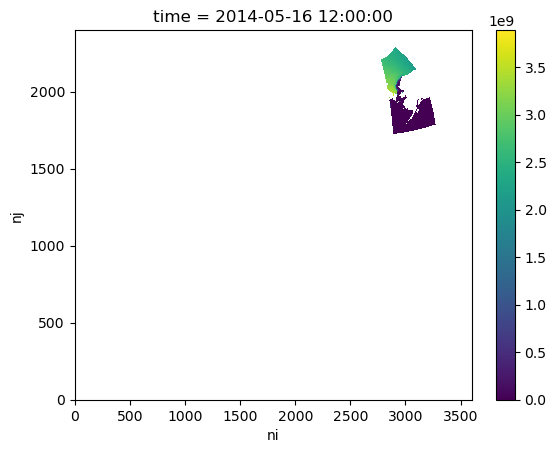

In [20]:
# make a mask for Pacific/Alaska area
ds_area_ak = ds_area.where((lats >= 50.0) & (lats <= 80.0) & (lons >= 180.0) & (lons <= 220.0))

# test plot
ds_area_ak.isel(member_id=0,time=100).plot()

In [21]:
# now sum up the total area in each region
total_area_nh = ds_area_nh.sum(dim=["nj","ni"])
total_area_nh.compute()
total_area_ak = ds_area_ak.sum(dim=["nj","ni"])
total_area_ak.compute()

/glade/u/apps/opt/conda/envs/npl-2024a/lib/python3.11/site-packages/distributed/client.py:3162: UserWarning: Sending large graph of size 262.96 MiB.
This may cause some slowdown.
Consider scattering data ahead of time and using futures.
  warnings.warn(
/glade/u/apps/opt/conda/envs/npl-2024a/lib/python3.11/site-packages/distributed/client.py:3162: UserWarning: Sending large graph of size 433.88 MiB.
This may cause some slowdown.
Consider scattering data ahead of time and using futures.
  warnings.warn(


<xarray.DataArray (member_id: 10, time: 1188)>
array([[1.6858980e+14, 1.9213298e+14, 2.1011020e+14, ..., 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00],
       [1.5261123e+14, 1.7768488e+14, 1.8930099e+14, ..., 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00],
       [1.6768911e+14, 1.8713107e+14, 1.8441608e+14, ..., 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00],
       ...,
       [1.4588828e+14, 1.4623998e+14, 1.4527519e+14, ..., 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00],
       [1.6096324e+14, 1.8049015e+14, 2.0165207e+14, ..., 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00],
       [1.4330868e+14, 1.6684321e+14, 1.4779236e+14, ..., 1.5743612e+04,
        5.8646856e+09, 2.5354914e+12]], dtype=float32)
Coordinates:
  * time     (time) object 2006-01-16 12:00:00 ... 2104-12-16 12:00:00
Dimensions without coordinates: member_id

In [ ]:
total_area_nh.isel(member_id=0).plot()

/glade/u/apps/opt/conda/envs/npl-2024a/lib/python3.11/site-packages/distributed/client.py:3162: UserWarning: Sending large graph of size 178.69 MiB.
This may cause some slowdown.
Consider scattering data ahead of time and using futures.
  warnings.warn(
Task exception was never retrieved
future: <Task finished name='Task-991125' coro=<Client._gather.<locals>.wait() done, defined at /glade/u/apps/opt/conda/envs/npl-2024a/lib/python3.11/site-packages/distributed/client.py:2208> exception=AllExit()>
Traceback (most recent call last):
  File "/glade/u/apps/opt/conda/envs/npl-2024a/lib/python3.11/site-packages/distributed/client.py", line 2217, in wait
    raise AllExit()
distributed.client.AllExit
Task exception was never retrieved
future: <Task finished name='Task-1001491' coro=<Client._gather.<locals>.wait() done, defined at /glade/u/apps/opt/conda/envs/npl-2024a/lib/python3.11/site-packages/distributed/client.py:2208> exception=AllExit()>
Traceback (most recent call last):
  File "/glad

## Put together into one dataset
- Put into a single netcdf for plotting

In [22]:
ds_out = xr.Dataset()

ds_out['SIA_nh'] = total_area_nh
ds_out['SIA_ak'] = total_area_ak

# change the attributes
ds_out.attrs['author'] = 'Alice DuVivier'
ds_out.attrs['date_processed'] = datetime.now().strftime('%Y-%m-%d')
ds_out.attrs['contents'] = f'Total Sea Ice Area (m^2) in different Arctic regions'

ds_out

<xarray.Dataset>
Dimensions:  (time: 1188, member_id: 10)
Coordinates:
  * time     (time) object 2006-01-16 12:00:00 ... 2104-12-16 12:00:00
Dimensions without coordinates: member_id
Data variables:
    SIA_nh   (member_id, time) float32 dask.array<chunksize=(1, 1), meta=np.ndarray>
    SIA_ak   (member_id, time) float32 dask.array<chunksize=(1, 1), meta=np.ndarray>
Attributes:
    author:          Alice DuVivier
    date_processed:  2025-12-08
    contents:        Total Sea Ice Area (m^2) in different Arctic regions

## Export and Save

In [23]:
# calculate the size of the dataset in GB
size_gb = ds_out.nbytes / (1024**3)
print(f"The dataset is approximately {size_gb:.2f} GB.")

The dataset is approximately 0.00 GB.


In [24]:
path_out = '/glade/campaign/cgd/ppc/duvivier/arctic_actionable/SOM_cyclones/validation/'
file_out = 'MESACLIP-SIA-future.nc'
fout = path_out + file_out

In [25]:
# Export the dataset to NetCDF with all attributes and coordinates
ds_out.to_netcdf(fout)


KeyboardInterrupt



In [ ]:
cluster.close()